# CPW transformer from (W1, S1) to (W2, S2)

Combines the two earlier approaches: a Klopfenstein impedance profile between the impedances of the two end geometries, with `W` following a chosen profile and the gap `S` solved at each section.

There are two design functions, because they answer different questions:

- `transformer_for_reflection`: the shortest transition that meets a reflection target.
- `transformer_for_length`: the lowest reflection at a given length.

Both optimise the Klopfenstein ripple on the cascaded network, because the continuous-taper formula doesn't quite hold for a staircase of sections.

**Limitation:** the circuit model has no step parasitics, mode conversion or radiation. It is reliable for the impedance match of long, gentle transitions, but short designs and the end steps need a full-wave check.

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import skrf as rf
from pathlib import Path
from skrf.mathFunctions import mag_2_db

from skrf_usimmics import Substrate, transformer_for_length, transformer_for_reflection, usimmics
from skrf_usimmics.plots import COLORS, GUIDE_COLOR, plot_outline, plot_profile, plot_s11

In [10]:
# End geometries and substrate (all lengths in m)
GEOMETRY = dict(w1=40e-6, s1=25e-6, w2=5e-6, s2=1e-6)
substrate = Substrate(h=500e-6, ep_r=11.7)

# Specification
F_C = 9e9               # lower passband edge
GAMMA_M_DB = -30.0      # reflection target from F_C to the top of the sweep

freq = rf.Frequency(0.1, 30, 401, 'GHz')
DESIGN = dict(f_c=F_C, substrate=substrate, frequency=freq)


def summarize(line):
    report = line.report
    print(f'Z0: {report["z1"]:.2f} -> {report["z2"]:.2f} ohm')
    print(f'Length: {line.length*1e3:.3f} mm in {report["n_sections"]} sections of {report["section_length"]*1e6:.1f} um')
    print(f'Peak |S11| from {report["f_c"]/1e9:g} to {report["f_max"]/1e9:g} GHz: {report["peak_s11_db"]:.2f} dB '
          f'(continuous-taper formula: {report["analytic_peak_db"]:.2f} dB)')
    print(f'Minimum gap: {report["min_gap"]*1e6:.2f} um')
    print(f'Steepest edge angle: inner {report["inner_edge_angle_deg"]:.2f} deg, outer {report["outer_edge_angle_deg"]:.2f} deg')
    print(f'Input step: S = {GEOMETRY["s1"]*1e6:.2f} -> {line.s[0]*1e6:.2f} um, Z0 = {report["z1"]:.2f} -> {line.z_sections[0]:.2f} ohm')
    if 'spec_met' in report:
        print(f'Target {report["target_db"]:.1f} dB met: {report["spec_met"]}. Length limited by: {report["limited_by"]}. '
              f'Formula estimate: {report["estimated_length"]*1e3:.3f} mm')

## Design for a reflection target

Finds the shortest length that meets the target. Optional limits: `max_length`, `max_sections`, `max_section_length`, and `max_edge_angle_deg`, which sets a minimum length (30 degrees by default).

Z0: 51.03 -> 37.03 ohm
Length: 5.036 mm in 26 sections of 193.7 um
Peak |S11| from 9 to 30 GHz: -30.05 dB (continuous-taper formula: -30.74 dB)
Minimum gap: 1.00 um
Steepest edge angle: inner 0.21 deg, outer 0.59 deg
Input step: S = 25.00 -> 22.43 um, Z0 = 51.03 -> 49.45 ohm
Target -30.0 dB met: True. Length limited by: reflection. Formula estimate: 4.854 mm


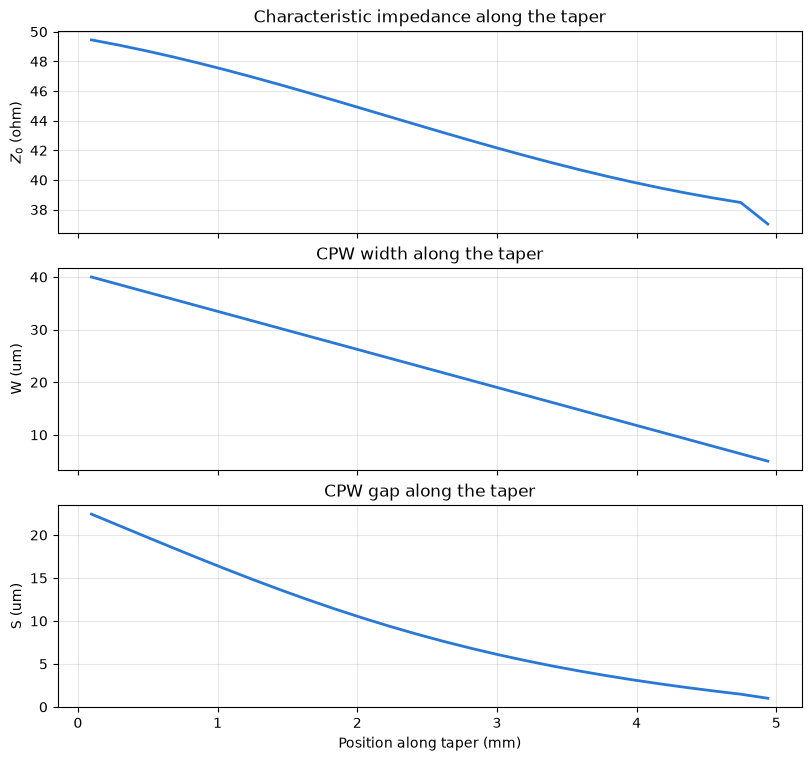

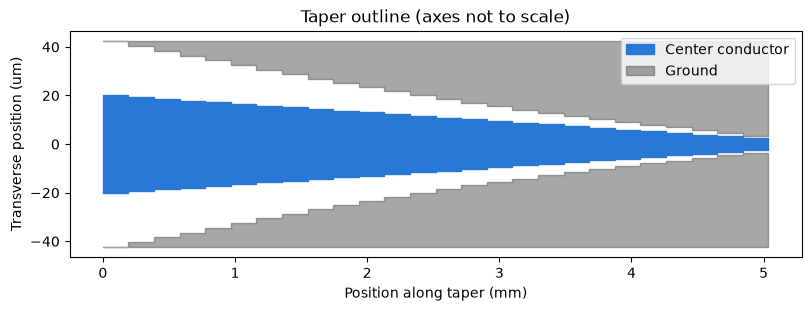

,Start (mm),End (mm),W (um),S (um),Z0 (ohm)
Section,,,,,
1,0.000,0.194,40.0,22.434,49.450
2,0.194,0.387,38.6,21.128,49.101
3,0.387,0.581,37.2,19.823,48.720
4,0.581,0.775,35.8,18.527,48.308
5,0.775,0.969,34.4,17.249,47.869
6,0.969,1.162,33.0,15.998,47.404
7,1.162,1.356,31.6,14.781,46.917
8,1.356,1.550,30.2,13.604,46.412
9,1.550,1.743,28.8,12.474,45.891


In [11]:
line = transformer_for_reflection(**GEOMETRY, gamma_m_db=GAMMA_M_DB, **DESIGN)
summarize(line)

plot_profile(line)
plot_outline(line)
plt.show()
display(line.table().round(3))

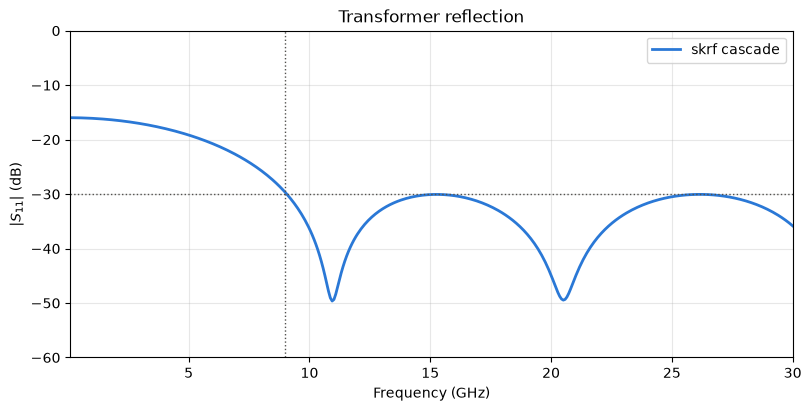

In [12]:
network = line.network(freq)
network.name = 'skrf cascade'

fig, ax = plot_s11([network], 'Transformer reflection')
ax.axhline(GAMMA_M_DB, color=GUIDE_COLOR, linewidth=1, linestyle=':')
ax.axvline(F_C, color=GUIDE_COLOR, linewidth=1, linestyle=':')
plt.show()

## Design for a fixed length

Gives the lowest reflection at this length. The number of sections follows from `max_section_length`, or wavelength/20 at the top of the band, capped at `max_sections`.

In [13]:
fixed = transformer_for_length(**GEOMETRY, length=5e-3, max_sections=35, **DESIGN)
summarize(fixed)

Z0: 51.03 -> 37.03 ohm
Length: 5.000 mm in 26 sections of 192.3 um
Peak |S11| from 9 to 30 GHz: -29.90 dB (continuous-taper formula: -30.59 dB)
Minimum gap: 1.00 um
Steepest edge angle: inner 0.21 deg, outer 0.60 deg
Input step: S = 25.00 -> 22.40 um, Z0 = 51.03 -> 49.42 ohm


## When the limits can't meet the target

With a 2 mm limit, the target isn't reachable. The function warns and returns the best line at the limit, with `report['spec_met']` set to False.

In [14]:
limited = transformer_for_reflection(**GEOMETRY, gamma_m_db=GAMMA_M_DB, max_length=5e-3, **DESIGN)
summarize(limited)

Z0: 51.03 -> 37.03 ohm
Length: 5.000 mm in 26 sections of 192.3 um
Peak |S11| from 9 to 30 GHz: -29.90 dB (continuous-taper formula: -30.59 dB)
Minimum gap: 1.00 um
Steepest edge angle: inner 0.21 deg, outer 0.60 deg
Input step: S = 25.00 -> 22.40 um, Z0 = 51.03 -> 49.42 ohm
Target -30.0 dB met: False. Length limited by: length limits. Formula estimate: 4.854 mm


C:\Users\kuksa\AppData\Local\Temp\ipykernel_16784\3139413452.py:1: UserWarning: Target -30.0 dB not met: best is -29.90 dB at L = 5.000 mm. Relax the length limits or the target.
  limited = transformer_for_reflection(**GEOMETRY, gamma_m_db=GAMMA_M_DB, max_length=5e-3, **DESIGN)


## Trade-offs

Reflection against length, and how few sections you can get away with at the length found above. The section table stops growing once sections reach wavelength/20 at the top of the band, because `max_sections` is only a limit. Pass a smaller `max_section_length` to use more.

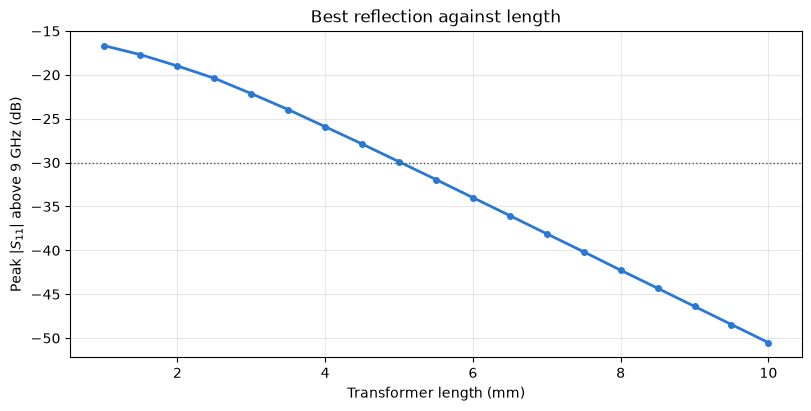

,Section (um),Peak |S11| (dB)
Sections,,
5,1007.27,-26.47
10,503.63,-28.69
15,335.76,-29.42
20,251.82,-29.79
26,193.71,-30.05


In [15]:
lengths = np.linspace(1e-3, 10e-3, 19)
peaks = [transformer_for_length(**GEOMETRY, length=length, **DESIGN).report['peak_s11_db'] for length in lengths]

fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
ax.plot(lengths * 1e3, peaks, color=COLORS[0], linewidth=2, marker='o', markersize=4)
ax.axhline(GAMMA_M_DB, color=GUIDE_COLOR, linewidth=1, linestyle=':')
ax.set_xlabel('Transformer length (mm)')
ax.set_ylabel(f'Peak $|S_{{11}}|$ above {F_C/1e9:g} GHz (dB)')
ax.set_title('Best reflection against length')
ax.grid(alpha=0.3)
plt.show()

rows = []
for max_sections in (5, 10, 15, 20, 30, 50, 100):
    result = transformer_for_length(**GEOMETRY, length=line.length, max_sections=max_sections, **DESIGN)
    rows.append({'Sections': result.report['n_sections'], 'Section (um)': result.report['section_length'] * 1e6,
                 'Peak |S11| (dB)': result.report['peak_s11_db']})
display(pd.DataFrame(rows).drop_duplicates('Sections').set_index('Sections').round(2))

## uSimmics schematic

Writes the reflection-target design, simulates it with the uSimmics engine and compares with skrf.

Not updated, differs from the design: P2
Schematic patched: C:\Users\kuksa\.qucs\CPW_transformer_prj\transformer.sch


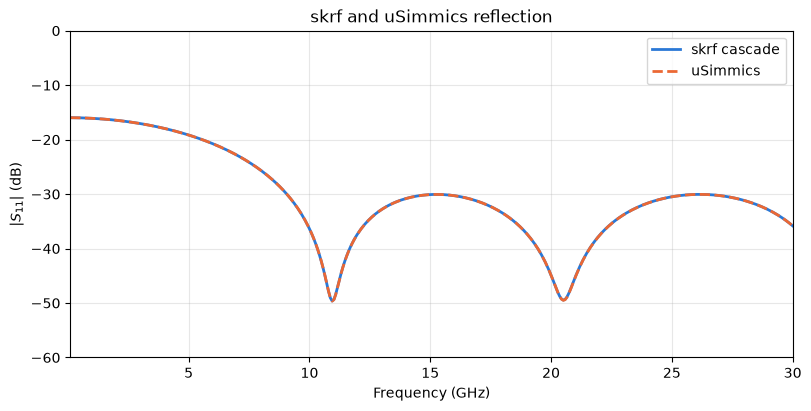

Max |S11 difference|, skrf vs uSimmics: 2.91e-05


In [16]:
SCH_PATH = Path.home() / '.qucs' / 'CPW_transformer_prj' / 'transformer.sch'

status = usimmics.write_schematic(SCH_PATH, line, freq)
print(f'Schematic {status}: {SCH_PATH}')

from_usimmics = usimmics.read_sp(usimmics.run_simulation(SCH_PATH), list(line.z_ports))

plot_s11([network, from_usimmics], 'skrf and uSimmics reflection')
plt.show()
print(f'Max |S11 difference|, skrf vs uSimmics: {np.abs(network.s[:, 0, 0] - from_usimmics.s[:, 0, 0]).max():.2e}')